# 🌿 Phân Loại Thực Vật: Hệ Thống Huấn Luyện AI Tiêu Chuẩn (Enterprise Pipeline)

Hệ thống được thiết kế: Tự động cài đặt môi trường, Chia tập dữ liệu Stratified Split, Cấu hình tập trung, Auto-Resume chống mất điện, Model Factory, Trực quan hóa Học thuật (Master Dashboard) và Xuất file Mô hình triển khai.


In [ ]:
# ==============================================================================
# CHƯƠNG 1: THIẾT LẬP MÔI TRƯỜNG & KẾT NỐI Ổ ĐĨA
# ==============================================================================
import os
import sys
import subprocess

try:
    from google.colab import drive
    IN_COLAB = True
    drive.mount('/content/drive')
except ImportError:
    IN_COLAB = False
    print("CẢNH BÁO: Môi trường hiện tại không phải là Google Colab.")

def check_gpu():
    import torch
    if not torch.cuda.is_available():
        raise Exception("KHÔNG TÌM THẤY GPU! Vui lòng chuyển Runtime của Colab sang GPU (T4, L4, hoặc A100).")
    gpu_name = torch.cuda.get_device_name(0)
    print(f"Đã nhận diện GPU: {gpu_name}")
    print(f"Tổng dung lượng VRAM: {torch.cuda.get_device_properties(0).total_memory / 1024**3:.2f} GB")

def install_deps():
    print("Đang cài đặt các thư viện MLOps cần thiết (vui lòng đợi)...")
    cmd = "pip install -q timm open_clip_torch albumentations torchmetrics grad-cam onnx onnxruntime rich onnxscript"
    subprocess.run(cmd, shell=True)
    print("Cài đặt thư viện hoàn tất!")

def prepare_dataset():
    zip_path = "/content/drive/MyDrive/Dudoancaycanh/dataset_sach.zip"
    extract_path = "/content/dataset"
    if IN_COLAB and os.path.exists(zip_path):
        if not os.path.exists(extract_path) or len(os.listdir(extract_path)) == 0:
            print(f"Đang tự động giải nén dữ liệu từ {zip_path}...")
            subprocess.run(f"unzip -q '{zip_path}' -d '{extract_path}'", shell=True)
            print("Giải nén hoàn tất!")
        else:
            print(f"Bộ dữ liệu đã sẵn sàng tại {extract_path}")
    else:
        print(f"Ghi chú: Không tìm thấy file {zip_path}. Vui lòng tự giải nén hoặc chỉnh cấu hình.")

install_deps()
check_gpu()
prepare_dataset()
print("\n===================================")
print("HỆ THỐNG ĐÃ SẴN SÀNG")
print("===================================")



Mounted at /content/drive
Đang cài đặt các thư viện MLOps cần thiết (vui lòng đợi)...
Cài đặt thư viện hoàn tất!
Đã nhận diện GPU: Tesla T4
Tổng dung lượng VRAM: 14.56 GB
Đang tự động giải nén dữ liệu từ /content/drive/MyDrive/Dudoancaycanh/dataset_sach.zip...
Giải nén hoàn tất!

HỆ THỐNG ĐÃ SẴN SÀNG


In [ ]:
# ==============================================================================
# CHƯƠNG 2: CẤU HÌNH DỰ ÁN TẬP TRUNG (MASTER CONFIG)
# ==============================================================================
import torch
import random
import numpy as np
import logging

# ---------------------------------------------------------
# 1. DANH SÁCH MÔ HÌNH SẼ CHẠY TỰ ĐỘNG NỐI TIẾP NHAU
# ---------------------------------------------------------
PROJECT_NAME     = "PhanLoaiThucVat"

# Bạn có thể bỏ bớt hoặc thêm các tên mô hình vào đây. Code sẽ tự chạy lần lượt từng con một!
# Các lựa chọn siêu việt: 'convnext_tiny', 'mobilenet_v3_large', 'efficientnet_v2_s', 'openclip_vit_b32'
MODELS_TO_TRAIN  = ["tf_efficientnetv2_b0", "ghostnetv2_100", "mobilevit_s"]

PRETRAINED       = True
IMAGE_SIZE       = 224
BATCH_SIZE       = 32
EPOCHS           = 50
LEARNING_RATE    = 1e-3
BACKBONE_LR      = 1e-4
WEIGHT_DECAY     = 1e-2
DROPOUT_RATE     = 0.5
MIXED_PRECISION  = True

# ---------------------------------------------------------
# 2. ĐƯỜNG DẪN HỆ THỐNG (ĐỒNG BỘ GOOGLE DRIVE)
# ---------------------------------------------------------
DRIVE_ROOT       = "/content/drive/MyDrive/Dudoancaycanh" if IN_COLAB else "./Dudoancaycanh"
DATASET_PATH     = "/content/dataset"

import os
# Tự động nội soi nhiều tầng (Vượt qua các thư mục lồng nhau)
if os.path.exists(DATASET_PATH):
    while True:
        dirs_inside = [d for d in os.listdir(DATASET_PATH) if os.path.isdir(os.path.join(DATASET_PATH, d))]
        files_inside = [f for f in os.listdir(DATASET_PATH) if f.lower().endswith(('.png', '.jpg', '.jpeg', '.webp'))]
        if len(dirs_inside) == 1 and len(files_inside) == 0:
            DATASET_PATH = os.path.join(DATASET_PATH, dirs_inside[0])
        else:
            break
    print(f"Đã dò tìm DATASET_PATH tại: {DATASET_PATH}")

DIRS = {
    "models": os.path.join(DRIVE_ROOT, "models"),
    "checkpoints": os.path.join(DRIVE_ROOT, "checkpoints"),
    "exports": os.path.join(DRIVE_ROOT, "exports"),
    "reports": os.path.join(DRIVE_ROOT, "reports"),
    "experiments": os.path.join(DRIVE_ROOT, "experiments")
}
for d in DIRS.values():
    os.makedirs(d, exist_ok=True)

# ---------------------------------------------------------
# 3. KIỂM SOÁT TÍNH TÁI LẬP (REPRODUCIBILITY) & CHỌN THIẾT BỊ
# ---------------------------------------------------------
def seed_everything(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True

seed_everything(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Cấu hình hoàn tất! Sẽ tự động chạy các Mô hình: {MODELS_TO_TRAIN}")



Đã dò tìm DATASET_PATH tại: /content/dataset/dataset_sach
Cấu hình hoàn tất! Sẽ tự động chạy các Mô hình: ['tf_efficientnetv2_b0', 'ghostnetv2_100', 'mobilevit_s']


In [ ]:
# ==============================================================================
# CHƯƠNG 3: TẠO DATA PIPELINE (MỘT LẦN DUY NHẤT CHO TẤT CẢ MÔ HÌNH)
# ==============================================================================
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, WeightedRandomSampler
from sklearn.model_selection import train_test_split
from PIL import Image
import numpy as np
import copy
import cv2

# Đọc Dataset
full_dataset = datasets.ImageFolder(DATASET_PATH)
classes = full_dataset.classes
NUM_CLASSES = len(classes)
print("======================================================")
print("BÁO CÁO PHÂN TÍCH BỘ DỮ LIỆU")
print("======================================================")
print(f"Số lượng loài cây: {NUM_CLASSES} loài (Ví dụ: {', '.join(classes[:5])}... )")
print(f"Tổng số lượng ảnh: {len(full_dataset):,} bức ảnh")

# Dùng chuẩn ImageNet thay vì tự tính
DATASET_MEAN = [0.485, 0.456, 0.406]
DATASET_STD = [0.229, 0.224, 0.225]
print(f"Giá trị RGB Mean: {DATASET_MEAN}")
print(f"Giá trị RGB Std:  {DATASET_STD}")

# Auto Crop Black Borders
class AutoCropBlackBorders(object):
    def __init__(self, threshold=15): self.threshold = threshold
    def __call__(self, img):
        gray = img.convert("L")
        mask = gray.point(lambda p: 255 if p > self.threshold else 0)
        bbox = mask.getbbox()
        if bbox: return img.crop(bbox)
        return img

train_transform = transforms.Compose([
    #AutoCropBlackBorders(15),
    transforms.Resize((IMAGE_SIZE+32, IMAGE_SIZE+32)),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.RandomCrop(IMAGE_SIZE),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(DATASET_MEAN, DATASET_STD),
    transforms.RandomErasing(p=0.5, scale=(0.02, 0.1))
])
val_transform = transforms.Compose([
    #AutoCropBlackBorders(15),
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(DATASET_MEAN, DATASET_STD)
])

# Chia Stratified Split 80/10/10
targets = [s[1] for s in full_dataset.samples]
train_idx, temp_idx = train_test_split(np.arange(len(targets)), test_size=0.2, stratify=targets, random_state=42)
temp_targets = [targets[i] for i in temp_idx]
val_idx, test_idx = train_test_split(temp_idx, test_size=0.5, stratify=temp_targets, random_state=42)

train_ds, val_ds, test_ds = copy.deepcopy(full_dataset), copy.deepcopy(full_dataset), copy.deepcopy(full_dataset)
train_ds.samples = [full_dataset.samples[i] for i in train_idx]; train_ds.transform = train_transform
val_ds.samples = [full_dataset.samples[i] for i in val_idx]; val_ds.transform = val_transform
test_ds.samples = [full_dataset.samples[i] for i in test_idx]; test_ds.transform = val_transform

# Weighted Random Sampler
class_counts_train = [0] * NUM_CLASSES
for _, label in train_ds.samples: class_counts_train[label] += 1
class_weights = [len(train_idx) / (NUM_CLASSES * c) if c > 0 else 0 for c in class_counts_train]
weights = [class_weights[label] for _, label in train_ds.samples]
sampler = WeightedRandomSampler(weights, num_samples=len(weights), replacement=True)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, sampler=sampler, num_workers=2, pin_memory=True, drop_last=True, persistent_workers=True)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True, persistent_workers=True)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True, persistent_workers=True)

print("======================================================")
print("CẤU TRÚC PHÂN BỔ DỮ LIỆU (STRATIFIED SPLIT)")
print("======================================================")
print(f"Tập Huấn Luyện (Train): {len(train_idx):,} ảnh (Chứa ảnh gốc + Đã Augmentation)")
print(f"Tập Kiểm Chứng (Val):   {len(val_idx):,} ảnh (Dùng để kiểm tra chéo mỗi vòng)")
print(f"Tập Đánh Giá (Test):    {len(test_idx):,} ảnh (Tuyệt mật - Chỉ dùng khi chấm điểm cuối cùng)")
print("Data Pipeline đã sẵn sàng đưa vào Huấn luyện!")



BÁO CÁO PHÂN TÍCH BỘ DỮ LIỆU
Số lượng loài cây: 40 loài (Ví dụ: Adenium obesum, Aglaonema commutatum, Alocasia amazonica, Alocasia macrorrhizos, Aloe vera... )
Tổng số lượng ảnh: 77,252 bức ảnh
Giá trị RGB Mean: [0.485, 0.456, 0.406]
Giá trị RGB Std:  [0.229, 0.224, 0.225]
CẤU TRÚC PHÂN BỔ DỮ LIỆU (STRATIFIED SPLIT)
Tập Huấn Luyện (Train): 61,801 ảnh (Chứa ảnh gốc + Đã Augmentation)
Tập Kiểm Chứng (Val):   7,725 ảnh (Dùng để kiểm tra chéo mỗi vòng)
Tập Đánh Giá (Test):    7,726 ảnh (Tuyệt mật - Chỉ dùng khi chấm điểm cuối cùng)
Data Pipeline đã sẵn sàng đưa vào Huấn luyện!



ĐANG VẼ BỨC TRANH TỔNG HỢP CỦA TẤT CẢ CÁC LOÀI...


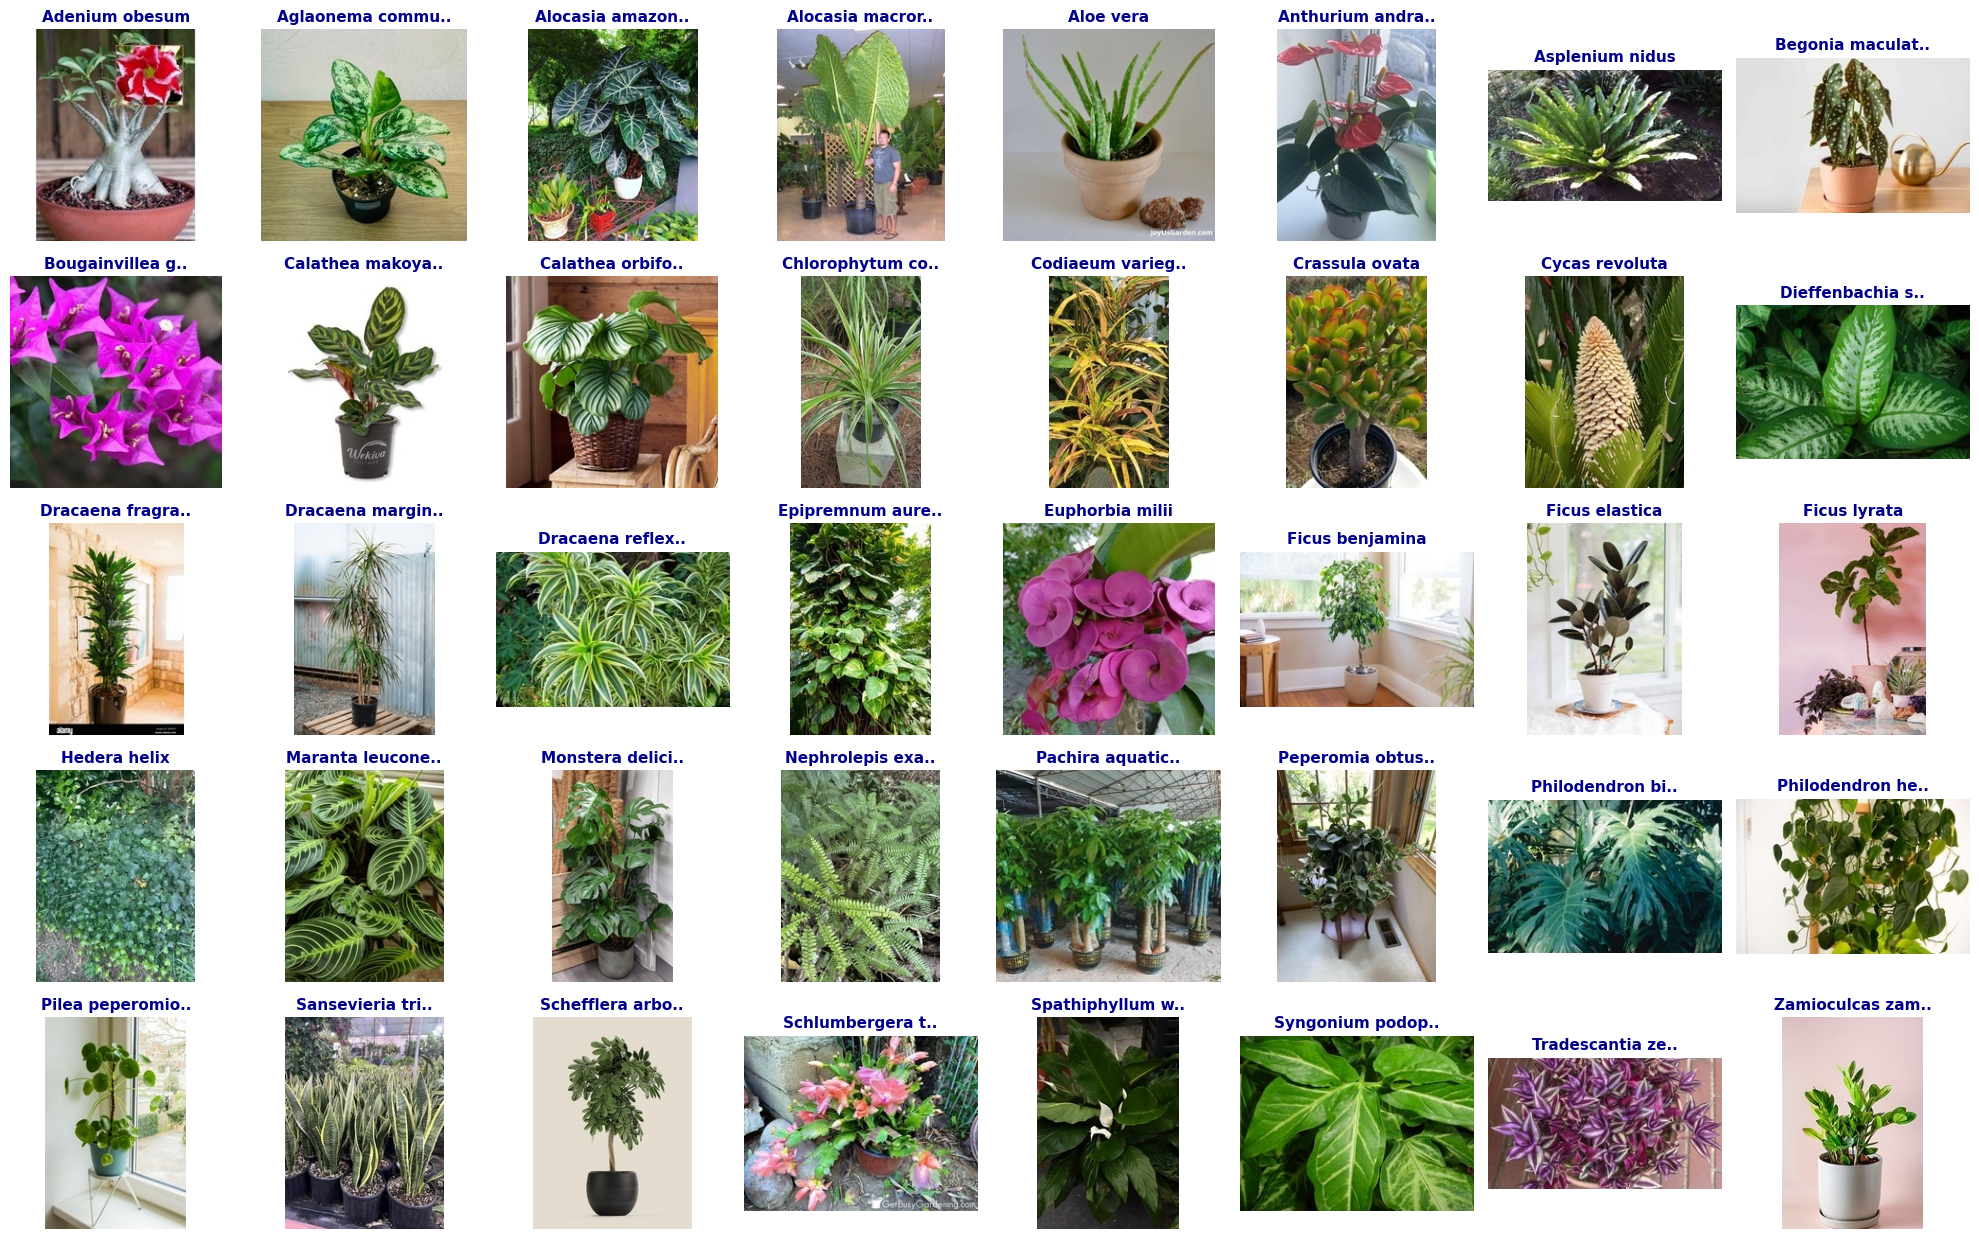

Đã lưu bức tranh đại diện siêu nét tại: /content/drive/MyDrive/Dudoancaycanh/reports/All_Classes_Preview.png

ĐANG VẼ BIỂU ĐỒ PHÂN BỐ SỐ LƯỢNG ẢNH...


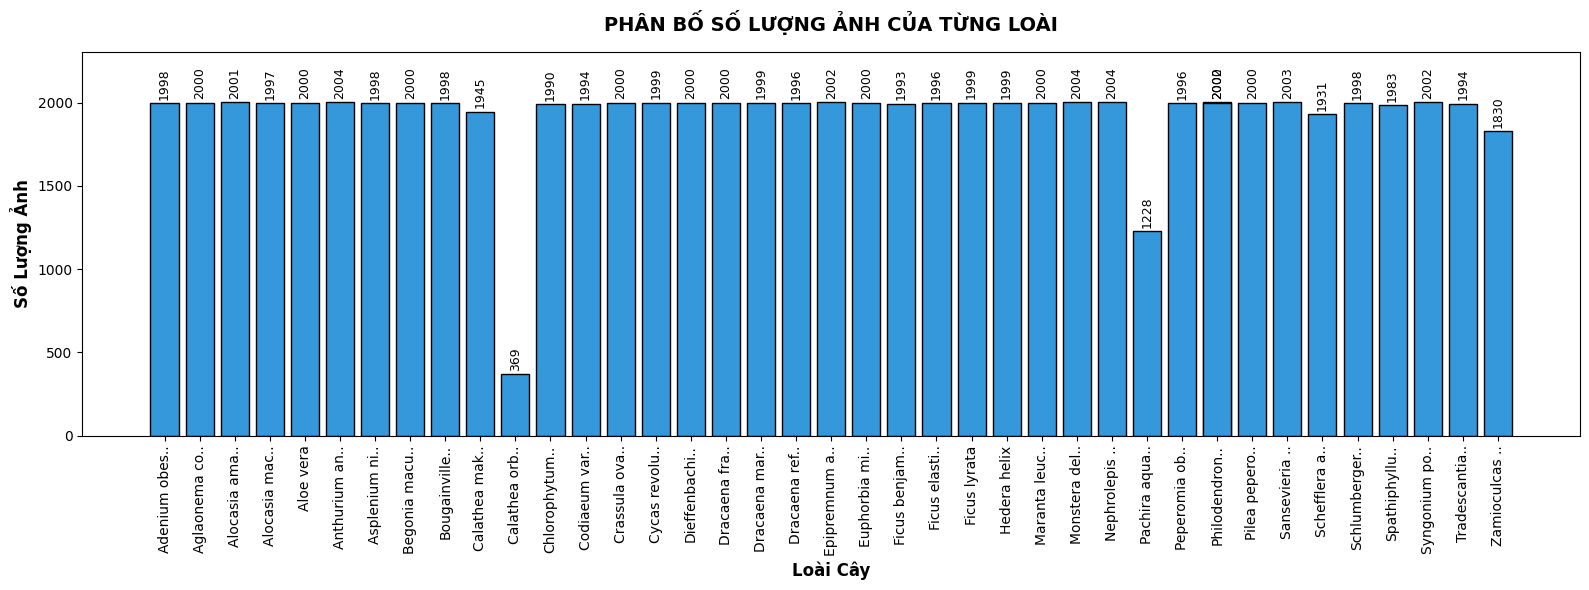

Đã lưu biểu đồ phân bố tại: /content/drive/MyDrive/Dudoancaycanh/reports/Data_Distribution.png



In [ ]:
import matplotlib.pyplot as plt
from PIL import Image
import os

print("\nĐANG VẼ BỨC TRANH TỔNG HỢP CỦA TẤT CẢ CÁC LOÀI...")
class_samples = {}
for path, label in full_dataset.samples:
    if label not in class_samples:
        class_samples[label] = path
    if len(class_samples) == NUM_CLASSES:
        break

cols = 8
rows = (NUM_CLASSES + cols - 1) // cols
fig, axes = plt.subplots(rows, cols, figsize=(cols*2.5, rows*2.5))
axes = axes.flatten()

for idx in range(len(axes)):
    if idx < NUM_CLASSES:
        img_path = class_samples[idx]
        img = Image.open(img_path).convert("RGB")
        axes[idx].imshow(img)
        class_name = classes[idx][:15] + ".." if len(classes[idx]) > 15 else classes[idx]
        axes[idx].set_title(class_name, fontsize=11, fontweight='bold', color='darkblue')
    axes[idx].axis('off')

plt.tight_layout()
sample_grid_path = os.path.join(DIRS['reports'], "All_Classes_Preview.png")
plt.savefig(sample_grid_path, dpi=150)
plt.show()
print(f"Đã lưu bức tranh đại diện siêu nét tại: {sample_grid_path}\n")

print("ĐANG VẼ BIỂU ĐỒ PHÂN BỐ SỐ LƯỢNG ẢNH...")
import collections
class_counts_dict = collections.Counter(targets)
counts = [class_counts_dict[i] for i in range(NUM_CLASSES)]
short_classes = [c[:12] + ".." if len(c) > 12 else c for c in classes]

plt.figure(figsize=(16, 6))
bars = plt.bar(short_classes, counts, color='#3498db', edgecolor='black')
plt.xticks(rotation=90, fontsize=10)
plt.title("PHÂN BỐ SỐ LƯỢNG ẢNH CỦA TỪNG LOÀI", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Loài Cây", fontsize=12, fontweight='bold')
plt.ylabel("Số Lượng Ảnh", fontsize=12, fontweight='bold')


for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + (max(counts)*0.01), int(yval),
             ha='center', va='bottom', fontsize=9, rotation=90)

plt.margins(y=0.15)
plt.tight_layout()
distribution_path = os.path.join(DIRS['reports'], "Data_Distribution.png")
plt.savefig(distribution_path, dpi=150)
plt.show()
print(f"Đã lưu biểu đồ phân bố tại: {distribution_path}\n")



In [ ]:
# ==============================================================================
# CHƯƠNG 4: VÒNG LẶP HUẤN LUYỆN ĐA MÔ HÌNH (AUTO EXPERIMENT RUNNER)
# ==============================================================================
import timm
import torch.nn as nn
import time
import datetime
import warnings
import os

warnings.filterwarnings("ignore")
os.environ['HF_HUB_DISABLE_WARNINGS'] = '1'
os.environ['HF_HUB_DISABLE_SYMLINKS_WARNING'] = '1'
logging.getLogger("huggingface_hub").setLevel(logging.ERROR)

from tqdm.auto import tqdm
from torch.amp import GradScaler, autocast
from sklearn.metrics import f1_score, precision_score, recall_score, confusion_matrix, roc_curve, ConfusionMatrixDisplay
from sklearn.preprocessing import label_binarize
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import torch.onnx
import gc

def build_model(model_name, num_classes):
    if "openclip" in model_name:
        import open_clip
        clip_model, _, _ = open_clip.create_model_and_transforms('ViT-B-32', pretrained='openai')
        model = nn.Sequential(clip_model.visual, nn.Dropout(DROPOUT_RATE), nn.Linear(512, num_classes))
        head = model[-1]
    else:
        model = timm.create_model(model_name, pretrained=True, num_classes=num_classes, drop_rate=DROPOUT_RATE)
        head = model.get_classifier()
    if hasattr(head, 'weight') and head.weight is not None: nn.init.xavier_uniform_(head.weight)
    if hasattr(head, 'bias') and head.bias is not None: nn.init.zeros_(head.bias)
    return model

# ---------------- VÒNG LẶP CHO TỪNG MÔ HÌNH ----------------
for current_model in MODELS_TO_TRAIN:
    print(f"\n{'='*60}")
    print(f"BẮT ĐẦU CHIẾN DỊCH HUẤN LUYỆN: {current_model.upper()}")
    print(f"{'='*60}")

    # 1. Khởi tạo Mô hình & Experiment Dir
    model = build_model(current_model, NUM_CLASSES).to(device)
    timestamp = datetime.datetime.now().strftime("%Y-%m-%d_%H-%M-%S")
    EXP_DIR = os.path.join(DIRS['experiments'], f"{timestamp}_{current_model}")
    os.makedirs(EXP_DIR, exist_ok=True)

    head_params = [p for n, p in model.named_parameters() if 'head' in n or 'classifier' in n or 'fc' in n]
    backbone_params = [p for n, p in model.named_parameters() if not ('head' in n or 'classifier' in n or 'fc' in n)]
    opt_params = [{'params': backbone_params, 'lr': BACKBONE_LR}, {'params': head_params, 'lr': LEARNING_RATE}]

    optimizer = torch.optim.AdamW(opt_params, weight_decay=WEIGHT_DECAY)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)
    criterion = nn.CrossEntropyLoss()
    scaler = GradScaler('cuda', enabled=MIXED_PRECISION)

    best_acc = 0.0
    start_epoch = 0
    history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
    prev_val_loss, prev_val_acc = "N/A", "N/A"

    # Tính năng Cứu hộ (Auto-Resume)
    last_ckpt_path = os.path.join(DIRS['checkpoints'], f'last_{current_model}.pth')
    if os.path.exists(last_ckpt_path):
        print(f"Đang phục hồi tiến độ cho {current_model}...")
        try:
            ckpt = torch.load(last_ckpt_path)
            model.load_state_dict(ckpt['model_state'])
            optimizer.load_state_dict(ckpt['optimizer_state'])
            scheduler.load_state_dict(ckpt['scheduler_state'])
            scaler.load_state_dict(ckpt['scaler_state'])
            start_epoch = ckpt['epoch'] + 1
            best_acc = ckpt['best_acc']
            history = ckpt['history']
            print(f"Đã khôi phục thành công! Học tiếp từ Vòng {start_epoch+1}")
        except Exception as e:
            print("Lỗi file cứu hộ, sẽ bắt đầu chạy lại từ đầu.")

    # 2. Huấn Luyện (Training Loop)
    for epoch in range(start_epoch, EPOCHS):
        since = time.time()

        # --- TRAIN ---
        model.train()
        train_loss, train_correct = 0.0, 0
        pbar = tqdm(train_loader, desc=f"[{current_model}] Vòng {epoch+1}/{EPOCHS}")
        for inputs, labels in pbar:
            inputs, labels = inputs.to(device), labels.to(device)
            optimizer.zero_grad()
            with autocast('cuda', enabled=MIXED_PRECISION):
                outputs = model(inputs)
                loss = criterion(outputs, labels)
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()

            train_loss += loss.item() * inputs.size(0)
            _, preds = torch.max(outputs, 1)
            train_correct += torch.sum(preds == labels.data).item()

            # Tính toán và hiển thị liên tục (Running Metrics)
            running_acc = train_correct / ((pbar.n + 1) * BATCH_SIZE)
            current_lr = optimizer.param_groups[0]['lr']
            pbar.set_postfix({
                'T_Loss': f"{loss.item():.4f}",
                'T_Acc': f"{running_acc*100:.1f}%",
                'V_Loss': prev_val_loss,
                'V_Acc': prev_val_acc,
                'LR': f"{current_lr:.1e}"
            })

        scheduler.step()
        epoch_train_loss = train_loss / len(train_ds)
        epoch_train_acc = train_correct / len(train_ds)

        # --- VAL ---
        model.eval()
        val_loss, val_correct = 0.0, 0
        with torch.no_grad():
            for inputs, labels in val_loader:
                inputs, labels = inputs.to(device), labels.to(device)
                with autocast('cuda', enabled=MIXED_PRECISION):
                    outputs = model(inputs)
                    loss = criterion(outputs, labels)
                val_loss += loss.item() * inputs.size(0)
                _, preds = torch.max(outputs, 1)
                val_correct += torch.sum(preds == labels.data).item()

        epoch_val_loss = val_loss / len(val_ds)
        epoch_val_acc = val_correct / len(val_ds)

        # Cập nhật cho thanh progress bar của vòng tiếp theo
        prev_val_loss = f"{epoch_val_loss:.4f}"
        prev_val_acc = f"{epoch_val_acc*100:.1f}%"

        # In ra tổng kết Epoch
        print(f"TỔNG KẾT VÒNG {epoch+1} | Train Loss: {epoch_train_loss:.4f} - Train Acc: {epoch_train_acc*100:.2f}% | Val Loss: {epoch_val_loss:.4f} - Val Acc: {epoch_val_acc*100:.2f}% | Thời gian: {time.time()-since:.0f}s")

        history['train_loss'].append(epoch_train_loss)
        history['val_loss'].append(epoch_val_loss)
        history['train_acc'].append(epoch_train_acc)
        history['val_acc'].append(epoch_val_acc)

        # Lưu File Cứu Hộ (Dùng để Auto-Resume nếu bị sập giữa chừng)
        torch.save({
            'epoch': epoch, 'model_state': model.state_dict(),
            'optimizer_state': optimizer.state_dict(), 'scheduler_state': scheduler.state_dict(),
            'scaler_state': scaler.state_dict(), 'best_acc': best_acc, 'history': history
        }, last_ckpt_path)

        if epoch_val_acc > best_acc:
            best_acc = epoch_val_acc
            torch.save(model.state_dict(), os.path.join(DIRS['checkpoints'], f'best_{current_model}.pth'))
            print("Kỷ lục mới! Đã lưu checkpoint.")

    # 3. Đánh Giá Độc Lập (Test Set) & Bảng Điều Khiển
    print(f"\nĐang vẽ Master Dashboard cho {current_model}...")
    model.load_state_dict(torch.load(os.path.join(DIRS['checkpoints'], f'best_{current_model}.pth')))
    model.eval()

    y_true, y_pred, y_conf = [], [], []
    start_time = time.time()
    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs = inputs.to(device)
            with autocast('cuda', enabled=MIXED_PRECISION): outputs = model(inputs)
            probs = torch.softmax(outputs, dim=1)
            conf, preds = torch.max(probs, 1)
            y_true.extend(labels.numpy())
            y_pred.extend(preds.cpu().numpy())
            y_conf.extend(conf.cpu().numpy())

    total_time = time.time() - start_time
    fps = len(test_ds) / total_time
    latency = total_time / len(test_ds) * 1000
    test_acc = sum(np.array(y_true) == np.array(y_pred)) / len(y_true)
    f1 = f1_score(y_true, y_pred, average='macro')
    prec = precision_score(y_true, y_pred, average='macro')
    rec = recall_score(y_true, y_pred, average='macro')

    # VẼ MASTER DASHBOARD
    fig = plt.figure(figsize=(24, 20))
    gs = gridspec.GridSpec(4, 2, height_ratios=[0.5, 3, 4, 1])
    fig.suptitle(f"BẢNG ĐIỀU KHIỂN: {current_model.upper()}", fontsize=28, fontweight='bold', y=0.98)

    ax_text = fig.add_subplot(gs[0, :])
    ax_text.axis('off')
    metrics_text = f"Accuracy: {test_acc*100:.2f}% | F1: {f1*100:.2f}% | Precision: {prec*100:.2f}% | Recall: {rec*100:.2f}%\nFPS: {fps:.0f} ảnh/s | Latency: {latency:.1f} ms"
    ax_text.text(0.5, 0.5, metrics_text, ha='center', va='center', fontsize=20, bbox=dict(boxstyle="round,pad=1", facecolor='#f8f9fa'))

    ax_loss = fig.add_subplot(gs[1, 0])
    ax_loss.plot(history['train_loss'], label='Train Loss', color='#007bff', lw=2.5)
    ax_loss.plot(history['val_loss'], label='Val Loss', color='#dc3545', lw=2.5)
    ax_loss.set_title("Loss Dynamics", fontsize=18, fontweight='bold'); ax_loss.legend(); ax_loss.grid(True)

    ax_acc = fig.add_subplot(gs[1, 1])
    ax_acc.plot(history['train_acc'], label='Train Acc', color='#007bff', lw=2.5)
    ax_acc.plot(history['val_acc'], label='Val Acc', color='#dc3545', lw=2.5)
    ax_acc.set_title("Accuracy Dynamics", fontsize=18, fontweight='bold'); ax_acc.legend(); ax_acc.grid(True)

    ax_cm = fig.add_subplot(gs[2, 0])
    disp = ConfusionMatrixDisplay(confusion_matrix=confusion_matrix(y_true, y_pred), display_labels=classes)
    disp.plot(ax=ax_cm, cmap='Blues', xticks_rotation=90, colorbar=False)
    ax_cm.set_title("Confusion Matrix", fontsize=18, fontweight='bold')

    ax_roc = fig.add_subplot(gs[2, 1])
    y_test_bin = label_binarize(y_true, classes=range(NUM_CLASSES))
    for i in range(min(5, NUM_CLASSES)):
        fpr, tpr, _ = roc_curve(y_test_bin[:, i], np.array(y_conf) * (np.array(y_pred)==i))
        ax_roc.plot(fpr, tpr, lw=2, label=f'{classes[i]}')
    ax_roc.plot([0, 1], [0, 1], color='gray', lw=2, linestyle='--')
    ax_roc.set_title("ROC Curve (Top 5)", fontsize=18, fontweight='bold'); ax_roc.legend(); ax_roc.grid(True)

    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.savefig(os.path.join(EXP_DIR, f"Dashboard_{current_model}.png"), dpi=300, bbox_inches='tight')
    plt.close(fig) # Đóng ảnh để giải phóng RAM

    # 4. Xuất File (ONNX / TorchScript)
    print("Đang xuất ONNX và TorchScript...")
    dummy_input = torch.randn(1, 3, IMAGE_SIZE, IMAGE_SIZE).to(device)
    torch.onnx.export(model, dummy_input, os.path.join(DIRS['exports'], f'{current_model}.onnx'), export_params=True)

    try: torch.jit.script(model).save(os.path.join(DIRS['exports'], f'{current_model}.ts'))
    except: torch.jit.trace(model, dummy_input).save(os.path.join(DIRS['exports'], f'{current_model}.ts'))

    with open(os.path.join(DIRS['exports'], "labels.txt"), "w", encoding="utf-8") as f:
        for c in classes: f.write(f"{c}\n")

    print(f"HOÀN THÀNH HUẤN LUYỆN: {current_model}!")

    # Lưu Metric để phục vụ cho so sánh đa mô hình
    import json
    with open(os.path.join(EXP_DIR, f"metrics_{current_model}.json"), "w") as f:
        json.dump({"Accuracy": test_acc, "F1": f1, "Precision": prec, "Recall": rec, "FPS": fps, "Latency": latency}, f)

    # 5. DỌN DẸP BỘ NHỚ ĐỂ NHƯỜNG CHỖ CHO MÔ HÌNH TIẾP THEO
    del model
    del optimizer
    del scheduler
    del scaler
    torch.cuda.empty_cache()
    gc.collect()

print("\nTẤT CẢ CÁC MÔ HÌNH ĐÃ ĐƯỢC HUẤN LUYỆN XONG VÀ LƯU VÀO GOOGLE DRIVE!")




BẮT ĐẦU CHIẾN DỊCH HUẤN LUYỆN: TF_EFFICIENTNETV2_B0


model.safetensors:   0%|          | 0.00/28.8M [00:00<?, ?B/s]

Đang phục hồi tiến độ cho tf_efficientnetv2_b0...
Đã khôi phục thành công! Học tiếp từ Vòng 24


[tf_efficientnetv2_b0] Vòng 24/50:   0%|          | 0/1931 [00:00<?, ?it/s]

TỔNG KẾT VÒNG 24 | Train Loss: 0.0397 - Train Acc: 98.71% | Val Loss: 0.5922 - Val Acc: 87.82% | Thời gian: 462s


[tf_efficientnetv2_b0] Vòng 25/50:   0%|          | 0/1931 [00:00<?, ?it/s]

... (30 outputs left out)

TỔNG KẾT VÒNG 40 | Train Loss: 0.0099 - Train Acc: 99.65% | Val Loss: 0.6507 - Val Acc: 89.27% | Thời gian: 438s


[tf_efficientnetv2_b0] Vòng 41/50:   0%|          | 0/1931 [00:00<?, ?it/s]

TỔNG KẾT VÒNG 41 | Train Loss: 0.0110 - Train Acc: 99.63% | Val Loss: 0.6430 - Val Acc: 89.28% | Thời gian: 437s


[tf_efficientnetv2_b0] Vòng 42/50:   0%|          | 0/1931 [00:00<?, ?it/s]

In [ ]:
# ==============================================================================
# CHƯƠNG 5: SO SÁNH TỔNG HỢP CÁC MÔ HÌNH (GLOBAL COMPARISON)
# ==============================================================================
import os
import json
import matplotlib.pyplot as plt
import numpy as np

print("ĐANG TỔNG HỢP KẾT QUẢ TỪ TẤT CẢ CÁC MÔ HÌNH...")

# Tìm tất cả các file metrics.json trong thư mục experiments
all_metrics = {}
for root, dirs, files in os.walk(DIRS['experiments']):
    for file in files:
        if file.startswith("metrics_") and file.endswith(".json"):
            model_n = file.replace("metrics_", "").replace(".json", "")
            with open(os.path.join(root, file), "r") as f:
                all_metrics[model_n] = json.load(f)

if len(all_metrics) > 1:
    models = list(all_metrics.keys())
    acc_scores = [all_metrics[m]['Accuracy']*100 for m in models]
    f1_scores = [all_metrics[m]['F1']*100 for m in models]
    fps_scores = [all_metrics[m]['FPS'] for m in models]

    fig, ax = plt.subplots(1, 2, figsize=(18, 6))

    # Biểu đồ 1: Accuracy & F1
    x = np.arange(len(models))
    width = 0.35
    ax[0].bar(x - width/2, acc_scores, width, label='Accuracy (%)', color='#007bff')
    ax[0].bar(x + width/2, f1_scores, width, label='F1 Score (%)', color='#28a745')
    ax[0].set_ylabel('Scores (%)')
    ax[0].set_title('Độ Chính Xác và Điểm F1 Giữa Các Mô Hình', fontweight='bold', fontsize=16)
    ax[0].set_xticks(x)
    ax[0].set_xticklabels(models, rotation=15, fontsize=12)
    ax[0].legend()
    ax[0].grid(axis='y', linestyle='--', alpha=0.7)

    # Biểu đồ 2: FPS (Tốc độ xử lý)
    ax[1].bar(x, fps_scores, color='#ffc107', edgecolor='black')
    ax[1].set_ylabel('Khung hình/Giây (FPS)')
    ax[1].set_title('Tốc Độ Xử Lý Thời Gian Thực (Càng cao càng mượt)', fontweight='bold', fontsize=16)
    ax[1].set_xticks(x)
    ax[1].set_xticklabels(models, rotation=15, fontsize=12)
    ax[1].grid(axis='y', linestyle='--', alpha=0.7)

    plt.tight_layout()
    compare_path = os.path.join(DRIVE_ROOT, "experiments", "GLOBAL_COMPARISON.png")
    plt.savefig(compare_path, dpi=300)
    plt.show()
    print(f"Đã xuất biểu đồ so sánh tổng hợp siêu nét tại: {compare_path}")
else:
    print("Cần ít nhất 2 mô hình đã hoàn thành để vẽ biểu đồ so sánh. Hiện tại chỉ có 1 mô hình.")

